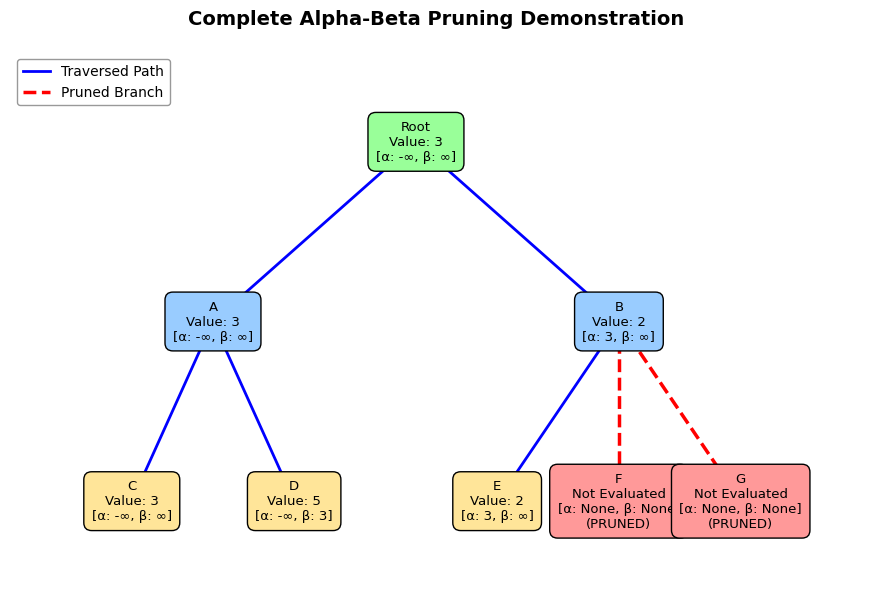

In [5]:
import math
import matplotlib.pyplot as plt

class LoggedNode:
    def __init__(self, name, value=None, children=None):
        self.name = name
        self.value = value
        self.children = children if children is not None else []
        self.alpha_at_eval = None
        self.beta_at_eval = None
        self.final_computed_value = None

    def is_terminal(self):
        return len(self.children) == 0

def alpha_beta_logged(node, depth, alpha, beta, is_max):
    node.alpha_at_eval = alpha
    node.beta_at_eval = beta

    if node.is_terminal() or depth == 0:
        node.final_computed_value = node.value
        return node.value

    if is_max:
        best = -math.inf
        for child in node.children:
            value = alpha_beta_logged(child, depth - 1, alpha, beta, False)
            best = max(best, value)
            alpha = max(alpha, best)
            if alpha >= beta:
                break
        node.final_computed_value = best
        return best
    else:
        best = math.inf
        for child in node.children:
            value = alpha_beta_logged(child, depth - 1, alpha, beta, True)
            best = min(best, value)
            beta = min(beta, best)
            if alpha >= beta:
                break
        node.final_computed_value = best
        return best

c_log = LoggedNode('C', value=3)
d_log = LoggedNode('D', value=5)
e_log = LoggedNode('E', value=2)
f_log = LoggedNode('F', value=6)
g_log = LoggedNode('G', value=8)

a_log = LoggedNode('A', children=[c_log, d_log])
b_log = LoggedNode('B', children=[e_log, f_log, g_log])

root_log = LoggedNode('Root', children=[a_log, b_log])

optimal_val = alpha_beta_logged(root_log, depth=2, alpha=-math.inf, beta=math.inf, is_max=True)

positions = {
    'Root': (0, 2),
    'A': (-2.5, 1),
    'B': (2.5, 1),
    'C': (-3.5, 0),
    'D': (-1.5, 0),
    'E': (1.0, 0),
    'F': (2.5, 0),
    'G': (4.0, 0)
}

def fmt(val):
    if val == math.inf:
        return '∞'
    if val == -math.inf:
        return '-∞'
    return str(val)

labels = {}
all_nodes = [root_log, a_log, b_log, c_log, d_log, e_log, f_log, g_log]
for n in all_nodes:
    pruned_suffix = "\n(PRUNED)" if n.final_computed_value is None else ""
    val_str = f"Value: {n.final_computed_value}" if n.final_computed_value is not None else "Not Evaluated"
    labels[n.name] = f"{n.name}\n{val_str}\n[α: {fmt(n.alpha_at_eval)}, β: {fmt(n.beta_at_eval)}]{pruned_suffix}"

fig, ax = plt.subplots(figsize=(11, 7))

edges = [
    ('Root', 'A', 'normal'),
    ('Root', 'B', 'normal'),
    ('A', 'C', 'normal'),
    ('A', 'D', 'normal'),
    ('B', 'E', 'normal'),
    ('B', 'F', 'pruned'),
    ('B', 'G', 'pruned')
]

for parent, child, style in edges:
    x1, y1 = positions[parent]
    x2, y2 = positions[child]
    if style == 'pruned':
        ax.plot([x1, x2], [y1, y2], color='red', linestyle='--', linewidth=2.5, label='Pruned Branch' if 'Pruned Branch' not in ax.get_legend_handles_labels()[1] else "")
    else:
        ax.plot([x1, x2], [y1, y2], color='blue', linewidth=2, label='Traversed Path' if 'Traversed Path' not in ax.get_legend_handles_labels()[1] else "")

for n in all_nodes:
    x, y = positions[n.name]
    if n.final_computed_value is None:
        color = '#ff9999'
    elif n.name == 'Root':
        color = '#99ff99'
    elif n.name in ['A', 'B']:
        color = '#99ccff'
    else:
        color = '#ffe599'

    ax.text(x, y, labels[n.name], bbox=dict(facecolor=color, edgecolor='black', boxstyle='round,pad=0.6'),
            ha='center', va='center', fontsize=9.5)

ax.set_xlim(-5, 5.5)
ax.set_ylim(-0.5, 2.5)
ax.axis('off')
ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='gray')
plt.title("Complete Alpha-Beta Pruning Demonstration", fontsize=14, fontweight='bold', pad=20)
plt.show()